# 13  -  Observational Trigger: Wind Exposure & Population

Evaluates the observational trigger for the Philippines AA Storms programme using historical IBTrACS track data.

For each historical WP typhoon (1980-2024) the notebook:
1. Builds asymmetric 64-kt wind footprints using observed radii (mean-infilled where missing)
2. Clips to the **four target regions** (Regions II, III, V, VIII / PH02, PH03, PH05, PH08)
3. Counts exposed admin-3 municipalities and sums WorldPop population
4. Calculates return periods for a sweep of population-exposure thresholds
5. Produces a year-by-year activation timeline

In [2]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.cm as cm
import matplotlib.colors as mcolors
import matplotlib.ticker as mticker
import matplotlib.patches as mpatches
import pandas as pd
import geopandas as gpd
import ocha_stratus as stratus
from shapely.geometry import LineString, Polygon
from shapely.ops import unary_union
from rasterstats import zonal_stats

In [3]:
# ── Constants ─────────────────────────────────────────────────────────────────
# IBTrACS WP wind_speed is JMA 10-min sustained in knots.
#
# KT_THRESHOLD is the minimum *centre* wind for a track point to be included.
# At 64 kt centre, the 64-kt radius is degenerate (≈ 0), so results are noisy.
# 100 kt = PAGASA super typhoon (≥ 185 kph 10-min sustained). At this intensity
# the 64-kt wind field extends well outward and is reliably observed in IBTrACS.
KT_THRESHOLD   = 100.0       # minimum centre-wind (kt) to include a track point
CRS_METRIC     = "EPSG:32651"  # UTM Zone 51N
HEADER_COLOR   = "#14805a"   # OCHA green
START_YEAR     = 1980
END_YEAR       = 2024

# Target regions
TARGET_REGIONS = ["PH02", "PH03", "PH05", "PH08"]

CONTAINER = "projects"
STAGE     = "dev"

print(f"KT threshold : {KT_THRESHOLD} kt ({KT_THRESHOLD * 1.852:.0f} km/h 10-min)  -  PAGASA super typhoon")
print(f"Record       : {START_YEAR}-{END_YEAR}  ({END_YEAR - START_YEAR + 1} years)")
print(f"Target regions: {TARGET_REGIONS}")

KT threshold : 100.0 kt (185 km/h 10-min)  -  PAGASA super typhoon
Record       : 1980-2024  (45 years)
Target regions: ['PH02', 'PH03', 'PH05', 'PH08']


In [4]:
# ── Admin boundaries ─────────────────────────────────────────────────────────
phl_admin_1 = stratus.codab.load_codab_from_fieldmaps(iso3="PHL", admin_level=1)
phl_admin_3 = stratus.codab.load_codab_from_fieldmaps(iso3="PHL", admin_level=3)

pcode_col = [c for c in phl_admin_1.columns if "src" in c.lower()][0]
target_regions_gdf = phl_admin_1[phl_admin_1[pcode_col].isin(TARGET_REGIONS)].copy()
target_union = unary_union(target_regions_gdf.geometry)
print(f"Target regions: {target_regions_gdf['adm1_name'].tolist()}")

# Identify the admin-1 pcode column in admin-3 for filtering
adm1_pcode_col_3 = [c for c in phl_admin_3.columns if "adm1" in c.lower() and "src" in c.lower()]
print(f"Admin-3 columns: {list(phl_admin_3.columns)}")

Target regions: ['Region II (Cagayan Valley)', 'Region III (Central Luzon)', 'Region V (Bicol Region)', 'Region VIII (Eastern Visayas)']
Admin-3 columns: ['fid', 'adm3_id', 'adm3_src', 'adm3_name', 'adm3_name1', 'adm3_name2', 'adm2_id', 'adm2_src', 'adm2_name', 'adm2_name1', 'adm2_name2', 'adm1_id', 'adm1_src', 'adm1_name', 'adm1_name1', 'adm1_name2', 'adm0_id', 'adm0_src', 'adm0_name', 'adm0_name1', 'adm0_name2', 'src_lvl', 'src_lang', 'src_lang1', 'src_lang2', 'src_date', 'src_update', 'src_name', 'src_name1', 'src_lic', 'src_url', 'src_grp', 'iso_cd', 'iso_2', 'iso_3', 'iso_3_grp', 'region3_cd', 'region3_nm', 'region2_cd', 'region2_nm', 'region1_cd', 'region1_nm', 'status_cd', 'status_nm', 'wld_date', 'wld_update', 'wld_view', 'wld_notes', 'geometry']


In [5]:
# ── Filter admin-3 to target regions ─────────────────────────────────────────
# Spatial join: keep admin-3 municipalities that fall within the target union
admin3_target = phl_admin_3[phl_admin_3.intersects(target_union)].copy()
admin3_target_proj = admin3_target.to_crs(CRS_METRIC)
print(f"All admin-3 : {len(phl_admin_3):,} municipalities")
print(f"In target regions: {len(admin3_target):,} municipalities")

All admin-3 : 1,641 municipalities
In target regions: 526 municipalities


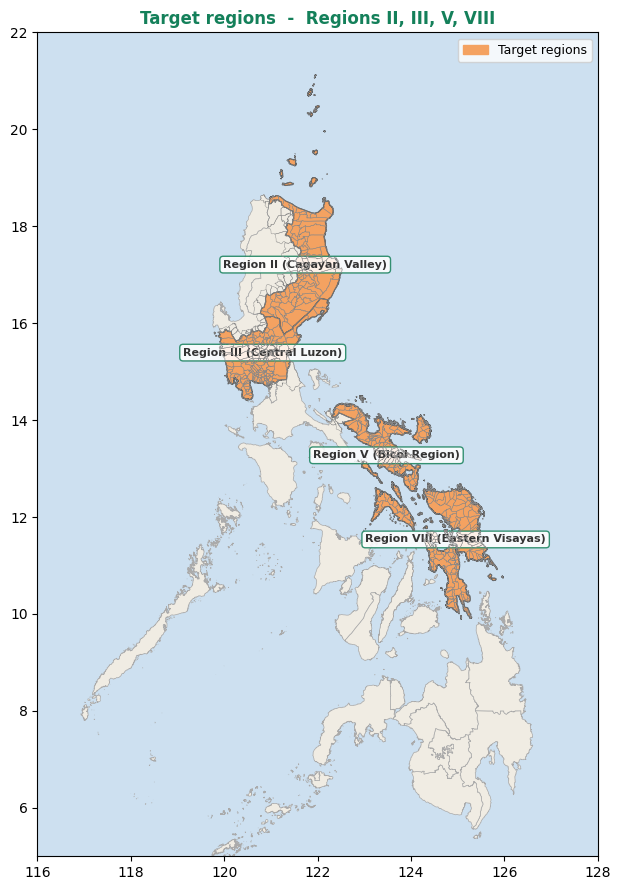

In [6]:
# ── Map: target regions with admin-3 outlines ─────────────────────────────────
fig, ax = plt.subplots(figsize=(7, 9))
ax.set_facecolor("#cde0f0")
phl_admin_1.plot(ax=ax, color="#f0ece3", edgecolor="#aaa", linewidth=0.5, zorder=2)
target_regions_gdf.plot(ax=ax, color="#f4a261", edgecolor="#555", linewidth=0.8, zorder=3)
admin3_target.plot(ax=ax, color="none", edgecolor="#888", linewidth=0.3, zorder=4)
for _, row in target_regions_gdf.iterrows():
    c = row.geometry.centroid
    ax.annotate(
        row["adm1_name"], xy=(c.x, c.y),
        ha="center", va="center", fontsize=8, fontweight="bold", color="#333",
        bbox=dict(boxstyle="round,pad=0.3", fc="white", ec=HEADER_COLOR, alpha=0.85),
    )
ax.set_xlim(116, 128); ax.set_ylim(5, 22)
ax.set_title("Target regions  -  Regions II, III, V, VIII",
             fontsize=12, fontweight="bold", color=HEADER_COLOR)
ax.legend(handles=[mpatches.Patch(color="#f4a261", label="Target regions")], fontsize=9)
plt.tight_layout()
plt.show()

In [7]:
# ── WorldPop raster ───────────────────────────────────────────────────────────
global_pop_raster = stratus.open_blob_cog(
    blob_name="worldpop/pop_count/global_pop_2026_CN_1km_R2025A_UA_v1.tif",
    stage="dev",
    container_name="raster",
)

minx, miny, maxx, maxy = admin3_target.total_bounds
pop_target = global_pop_raster.rio.clip_box(
    minx=minx - 0.1, miny=miny - 0.1,
    maxx=maxx + 0.1, maxy=maxy + 0.1,
)
print(f"Clipped raster shape: {pop_target.shape}  CRS: {pop_target.rio.crs}")

# Expose these for reuse in later cells (footprint zonal_stats and per-region breakdown)
pop_array     = pop_target.values.squeeze().astype(float)
pop_transform = pop_target.rio.transform()
nodata_val    = pop_target.rio.nodata

# Total population in target regions (reference, from raster)
target_stats = zonal_stats(
    admin3_target.to_crs(pop_target.rio.crs),
    pop_array, affine=pop_transform,
    stats=["sum"], nodata=nodata_val, all_touched=True,
)
total_pop = int(round(sum(s["sum"] or 0 for s in target_stats)))
print(f"Total population in target regions: {total_pop:,.0f}")

# Per-municipality population  -  used only for the case-study map (cell 19)
admin3_target_pop = admin3_target.copy()
admin3_target_pop["population"] = [
    int(round(s["sum"])) if s["sum"] is not None else 0 for s in target_stats
]

Clipped raster shape: (1, 1372, 767)  CRS: GEOGCS["WGS 84",DATUM["World Geodetic System 1984",SPHEROID["WGS 84",6378137,298.257223563]],PRIMEM["Greenwich",0],UNIT["degree",0.0174532925199433,AUTHORITY["EPSG","9122"]],AXIS["Latitude",NORTH],AXIS["Longitude",EAST]]
Total population in target regions: 42,324,903


In [8]:
# ── IBTrACS track data ────────────────────────────────────────────────────────
def fetch_ibtracs(start_date, end_date):
    query = f"""
    SELECT *
    FROM storms.ibtracs_tracks_geo
    WHERE basin = 'WP'
      AND valid_time BETWEEN '{start_date}' AND '{end_date}'
    """
    return gpd.read_postgis(
        query, stratus.get_engine(stage="prod"), geom_col="geometry"
    )

tracks_hist = fetch_ibtracs(f"{START_YEAR}-01-01", f"{END_YEAR}-12-31")
print(f"Track points : {len(tracks_hist):,}")
print(f"Date range   : {tracks_hist['valid_time'].min().date()} → {tracks_hist['valid_time'].max().date()}")
print(f"Unique storms: {tracks_hist['storm_id'].nunique()}")
print(f"Columns      : {list(tracks_hist.columns)}")

Track points : 71,673
Date range   : 1980-04-05 → 2024-12-25
Unique storms: 1127
Columns      : ['sid', 'point_id', 'storm_id', 'valid_time', 'provider', 'basin', 'nature', 'wind_speed', 'pressure', 'max_wind_radius', 'last_closed_isobar_radius', 'last_closed_isobar_pressure', 'gust_speed', 'quadrant_radius_34', 'quadrant_radius_50', 'quadrant_radius_64', 'usa_quadrant_radius_34', 'usa_quadrant_radius_50', 'usa_quadrant_radius_64', 'geometry']


In [9]:
# ── Parse 64-kt wind radii ────────────────────────────────────────────────────
def parse_radii(val):
    if val is None:
        return None
    parts = str(val).strip("{}").split(",")
    vals = []
    for p in parts:
        try:
            v = float(p.strip())
            vals.append(np.nan if np.isnan(v) else v)
        except ValueError:
            vals.append(np.nan)
    return vals if any(not np.isnan(v) for v in vals) else None


def wind_polygon_utm(x, y, radii_nm):
    nm2m = 1852.0
    valid = [r * nm2m for r in radii_nm if not np.isnan(r)]
    fill  = float(np.mean(valid))
    rm    = [r * nm2m if not np.isnan(r) else fill for r in radii_nm]
    pts = []
    for deg in np.linspace(0, 360, 360, endpoint=False):
        if   deg <  90: r = rm[0]
        elif deg < 180: r = rm[1]
        elif deg < 270: r = rm[2]
        else:           r = rm[3]
        rad = np.radians(90 - deg)
        pts.append((x + r * np.cos(rad), y + r * np.sin(rad)))
    poly = Polygon(pts)
    return poly if poly.is_valid else poly.buffer(0)


# Detect the 64-kt radius columns (PostgreSQL array strings)
r64_cols = sorted([c for c in tracks_hist.columns if "radius_64" in c.lower()])
print("64-kt radius columns:")
for col in r64_cols:
    n_valid = tracks_hist[col].apply(lambda v: parse_radii(v) is not None).sum()
    print(f"  {col}: {n_valid:,} / {len(tracks_hist):,} valid  ({n_valid/len(tracks_hist)*100:.1f}%)")

64-kt radius columns:
  quadrant_radius_64: 0 / 71,673 valid  (0.0%)
  usa_quadrant_radius_64: 4,877 / 71,673 valid  (6.8%)


In [10]:
# ── Mean-infill radii ─────────────────────────────────────────────────────────
# Identify which 64-kt column has the best coverage and use it
best_col = max(r64_cols, key=lambda c: tracks_hist[c].apply(lambda v: parse_radii(v) is not None).sum())
tracks_hist["_radii_64"] = tracks_hist[best_col].apply(parse_radii)
print(f"Using column: {best_col}")

valid_radii = tracks_hist["_radii_64"].dropna().tolist()
mean_radii  = [
    float(np.nanmean([r[i] for r in valid_radii])) for i in range(4)
]
print("Mean 64-kt radii used as infill (NE / SE / SW / NW):")
print("  " + " / ".join(f"{r:.0f} nm" for r in mean_radii))

Using column: usa_quadrant_radius_64
Mean 64-kt radii used as infill (NE / SE / SW / NW):
  41 nm / 38 nm / 35 nm / 38 nm


In [11]:
# ── Build wind footprints clipped to target regions ───────────────────────────
pts = gpd.GeoDataFrame(
    tracks_hist[tracks_hist["wind_speed"] >= KT_THRESHOLD].copy(),
    geometry="geometry", crs="EPSG:4326",
).to_crs(CRS_METRIC)

target_union_proj = target_regions_gdf.to_crs(CRS_METRIC).union_all()

print(f"Track points ≥ {KT_THRESHOLD:.0f} kt : {len(pts):,}")
n_obs    = pts["_radii_64"].notna().sum()
n_filled = pts["_radii_64"].isna().sum()
print(f"  Observed radii : {n_obs:,} ({n_obs/len(pts)*100:.1f}%)")
print(f"  Mean-filled    : {n_filled:,} ({n_filled/len(pts)*100:.1f}%)")

polys = []
for _, row in pts.iterrows():
    radii = row["_radii_64"] if row["_radii_64"] is not None else mean_radii
    poly  = wind_polygon_utm(row.geometry.x, row.geometry.y, radii)
    if poly is not None:
        polys.append({"storm_id": row["storm_id"], "geometry": poly})

wind_polys = gpd.GeoDataFrame(polys, crs=CRS_METRIC)

# Dissolve to one footprint per storm, then clip to target regions
footprints = wind_polys.dissolve(by="storm_id").reset_index()[["storm_id", "geometry"]]
footprints["geometry"] = footprints["geometry"].intersection(target_union_proj)
footprints = footprints[~footprints["geometry"].is_empty].copy()
print(f"Storms with target-region exposure: {len(footprints):,}")

Track points ≥ 100 kt : 1,184
  Observed radii : 632 (53.4%)
  Mean-filled    : 552 (46.6%)
Storms with target-region exposure: 30


In [22]:
# ── Spatial join: which target-region municipalities were exposed? ─────────────
joined = gpd.sjoin(admin3_target_proj, footprints, how="inner", predicate="intersects")

muni_count = (
    joined.groupby("storm_id")
    .apply(lambda x: x.index.nunique(), include_groups=False)
    .reset_index(name="n_munis")
)

# Max wind speed and year per storm
storm_meta = (
    tracks_hist.groupby("storm_id")
    .agg(max_wind_kt=("wind_speed", "max"))
    .reset_index()
)
storm_meta["max_wind_kmh"] = (storm_meta["max_wind_kt"] * 1.852).round(1)
storm_meta["name"] = storm_meta["storm_id"].str.split("_").str[0].str.capitalize()
storm_meta["year"] = storm_meta["storm_id"].str.extract(r"_wp_(\d{4})$")

muni_count = muni_count.merge(storm_meta, on="storm_id")

# Population exposed: intersect the actual wind footprint with the population raster
# (counts only pixels inside the 64-kt wind area, not entire municipality populations)
footprints_raster_crs = footprints.to_crs(pop_target.rio.crs).reset_index(drop=True)
fp_stats = zonal_stats(
    footprints_raster_crs,
    pop_array, affine=pop_transform,
    stats=["sum"], nodata=nodata_val, all_touched=True,
)
fp_pop = pd.DataFrame({
    "storm_id": footprints["storm_id"].values,
    "population_exposed": [
        int(round(s["sum"])) if s["sum"] is not None else 0 for s in fp_stats
    ],
})
muni_count = muni_count.merge(fp_pop, on="storm_id", how="left")
muni_count["population_exposed"] = muni_count["population_exposed"].fillna(0).astype(int)

exposure = (
    muni_count[["storm_id", "name", "year", "max_wind_kmh", "n_munis", "population_exposed"]]
    .sort_values("population_exposed", ascending=False)
    .reset_index(drop=True)
)
exposure.index += 1
print(f"Storms with target-region exposure: {len(exposure)}")
print(f"Total years: {exposure['year'].dropna().nunique()}")

Storms with target-region exposure: 30
Total years: 20


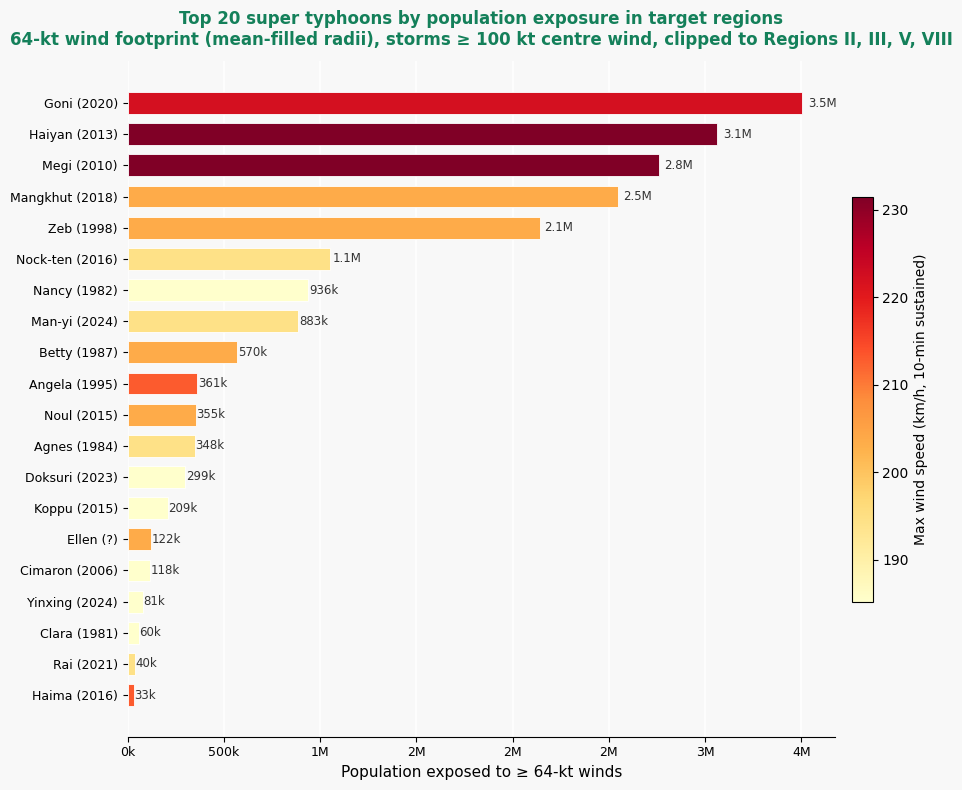

In [23]:
# ── Top 20 storms by population exposed ──────────────────────────────────────
TOP_N = 20
plot_df = exposure.head(TOP_N).copy()
plot_df["bar_label"] = plot_df["name"] + " (" + plot_df["year"].fillna("?") + ")"

norm_w  = mcolors.Normalize(
    vmin=plot_df["max_wind_kmh"].min(),
    vmax=plot_df["max_wind_kmh"].max(),
)
colors = [cm.YlOrRd(norm_w(v)) for v in plot_df["max_wind_kmh"]]

fig, ax = plt.subplots(figsize=(10, 8))
fig.patch.set_facecolor("#f8f8f8")
ax.set_facecolor("#f8f8f8")

bars = ax.barh(
    plot_df["bar_label"][::-1], plot_df["population_exposed"][::-1],
    color=colors[::-1], edgecolor="white", linewidth=0.6, height=0.7,
)
for bar, val in zip(bars, plot_df["population_exposed"][::-1]):
    ax.text(
        bar.get_width() * 1.01, bar.get_y() + bar.get_height() / 2,
        f"{val/1e6:.1f}M" if val >= 1e6 else f"{val/1e3:.0f}k",
        va="center", ha="left", fontsize=8.5, color="#333",
    )

sm = cm.ScalarMappable(cmap=cm.YlOrRd, norm=norm_w)
sm.set_array([])
fig.colorbar(sm, ax=ax, shrink=0.6, pad=0.02, aspect=20,
             label="Max wind speed (km/h, 10-min sustained)")

ax.xaxis.set_major_formatter(mticker.FuncFormatter(
    lambda x, _: f"{x/1e6:.0f}M" if x >= 1e6 else f"{x/1e3:.0f}k"
))
ax.set_xlabel("Population exposed to ≥ 64-kt winds", fontsize=11)
ax.set_title(
    f"Top {TOP_N} super typhoons by population exposure in target regions\n"
    f"64-kt wind footprint (mean-filled radii), storms ≥ {KT_THRESHOLD:.0f} kt centre wind, "
    f"clipped to Regions II, III, V, VIII",
    fontsize=12, fontweight="bold", pad=12, color=HEADER_COLOR,
)
ax.spines[["top", "right", "left"]].set_visible(False)
ax.xaxis.grid(True, color="white", linewidth=1.2)
ax.set_axisbelow(True)
ax.tick_params(labelsize=9)
plt.tight_layout()
plt.show()

Record length: 45 years  |  Storms ranked: 30


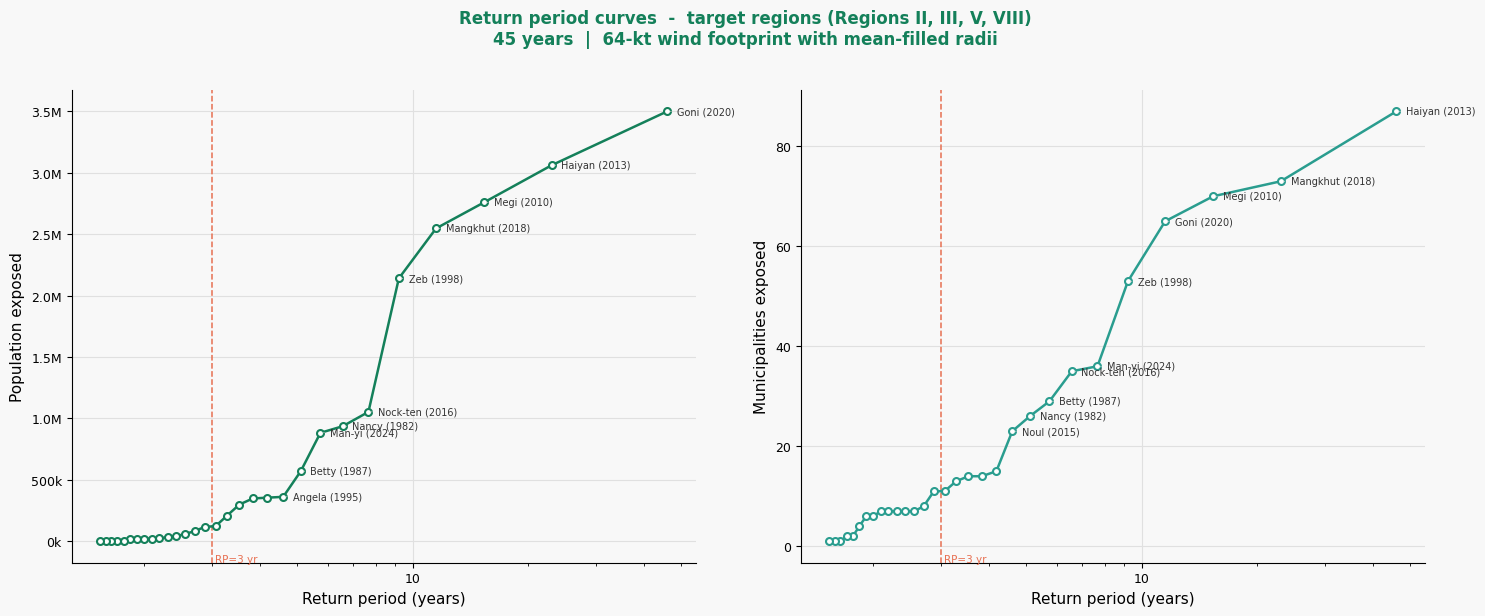

In [24]:
# ── Return period curves ──────────────────────────────────────────────────────
N_YEARS = END_YEAR - START_YEAR + 1
print(f"Record length: {N_YEARS} years  |  Storms ranked: {len(exposure)}")

def compute_rp(series, n_years):
    s = series.sort_values(ascending=False).reset_index(drop=True)
    s.index += 1
    rp = (n_years + 1) / s.index.values
    return s.values, rp

pop_vals, pop_rp = compute_rp(exposure["population_exposed"], N_YEARS)
muni_vals, muni_rp = compute_rp(exposure["n_munis"], N_YEARS)

# ── Labels: top 10 storms ────────────────────────────────────────────────────
def top_labels(df, col, n=10):
    top = df.nlargest(n, col)
    return list(zip(top[col].values, (top["name"] + " (" + top["year"].fillna("?") + ")").values))

pop_labels  = top_labels(exposure, "population_exposed")
muni_labels = top_labels(exposure, "n_munis")

fig, axes = plt.subplots(1, 2, figsize=(15, 6))
fig.patch.set_facecolor("#f8f8f8")

for ax, vals, rp_yrs, labels, ylabel, color in [
    (axes[0], pop_vals,  pop_rp,  pop_labels,  "Population exposed",       HEADER_COLOR),
    (axes[1], muni_vals, muni_rp, muni_labels, "Municipalities exposed",   "#2a9d8f"),
]:
    ax.set_facecolor("#f8f8f8")
    ax.plot(rp_yrs, vals, "o-", color=color, linewidth=1.8,
            markersize=5, markerfacecolor="white", markeredgewidth=1.5, zorder=3)

    for val, label in labels:
        idx  = np.argmin(np.abs(vals - val))
        rp_v = rp_yrs[idx]
        ax.annotate(
            label, xy=(rp_v, val),
            xytext=(7, 0), textcoords="offset points",
            fontsize=7, color="#333", va="center",
            arrowprops=dict(arrowstyle="-", color="#ccc", lw=0.5),
        )

    ax.set_xscale("log")
    ax.xaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f"{x:g}"))
    ax.xaxis.set_minor_formatter(mticker.NullFormatter())
    ax.set_xlabel("Return period (years)", fontsize=11)
    ax.set_ylabel(ylabel, fontsize=11)
    if ylabel == "Population exposed":
        ax.yaxis.set_major_formatter(mticker.FuncFormatter(
            lambda x, _: f"{x/1e6:.1f}M" if x >= 1e6 else f"{x/1e3:.0f}k"
        ))
    ax.axvline(3, color="#e76f51", linewidth=1.1, linestyle="--", zorder=2)
    ax.text(3.05, ax.get_ylim()[0] * 1.05, "RP=3 yr",
            fontsize=7.5, color="#e76f51", va="bottom")
    ax.xaxis.grid(True, color="#e0e0e0", linewidth=0.8)
    ax.yaxis.grid(True, color="#e0e0e0", linewidth=0.8)
    ax.set_axisbelow(True)
    ax.spines[["top", "right"]].set_visible(False)
    ax.tick_params(labelsize=9)

fig.suptitle(
    f"Return period curves  -  target regions (Regions II, III, V, VIII)\n"
    f"{N_YEARS} years  |  64-kt wind footprint with mean-filled radii",
    fontsize=12, fontweight="bold", y=1.02, color=HEADER_COLOR,
)
plt.tight_layout()
plt.show()

In [25]:
# ── Population threshold sweep: RP at each threshold ─────────────────────────
# For each candidate population threshold, count how many seasons had
# at least one storm exceeding that threshold in the target regions.
# RP = N_years / n_activated_seasons

thresholds = [
    100_000, 250_000, 500_000, 750_000,
    1_000_000, 1_500_000, 2_000_000, 3_000_000, 5_000_000,
]

exposure_with_year = exposure.copy()
exposure_with_year["year_int"] = exposure_with_year["year"].dropna().astype(int)

rows = []
for thr in thresholds:
    above = exposure_with_year[exposure_with_year["population_exposed"] >= thr]
    n_seasons = above["year_int"].nunique()
    rp = N_YEARS / n_seasons if n_seasons > 0 else float("inf")
    rows.append({
        "threshold": thr,
        "n_seasons": n_seasons,
        "rp_yr": round(rp, 1),
        "storms": len(above),
    })

sweep_df = pd.DataFrame(rows)
print("Population threshold sweep:")
print(
    sweep_df.assign(
        threshold=lambda d: d["threshold"].apply(lambda v: f"{v/1e6:.2f}M" if v >= 1e6 else f"{v/1e3:.0f}k")
    ).to_string(index=False)
)

Population threshold sweep:
threshold  n_seasons  rp_yr  storms
     100k         14    3.2      16
     250k         13    3.5      13
     500k          9    5.0       9
     750k          8    5.6       8
    1.00M          6    7.5       6
    1.50M          5    9.0       5
    2.00M          5    9.0       5
    3.00M          2   22.5       2
    5.00M          0    inf       0


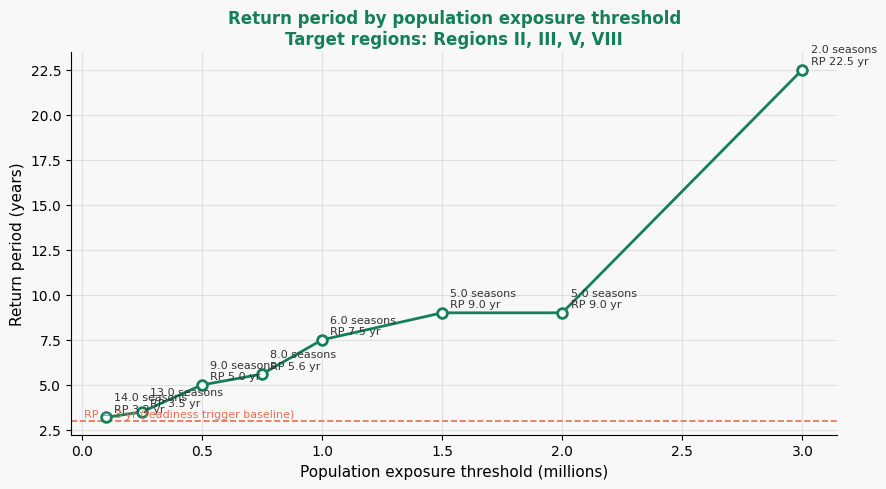

In [26]:
# ── Plot: RP vs population threshold ─────────────────────────────────────────
fig, ax = plt.subplots(figsize=(9, 5))
fig.patch.set_facecolor("#f8f8f8")
ax.set_facecolor("#f8f8f8")

finite_mask = sweep_df["rp_yr"] < 100
ax.plot(
    sweep_df.loc[finite_mask, "threshold"] / 1e6,
    sweep_df.loc[finite_mask, "rp_yr"],
    "o-", color=HEADER_COLOR, linewidth=2,
    markersize=7, markerfacecolor="white", markeredgewidth=2, zorder=3,
)
for _, row in sweep_df[finite_mask].iterrows():
    ax.annotate(
        f"{row['n_seasons']} seasons\nRP {row['rp_yr']} yr",
        xy=(row["threshold"] / 1e6, row["rp_yr"]),
        xytext=(6, 4), textcoords="offset points",
        fontsize=8, color="#333",
    )

ax.axhline(3.0, color="#e76f51", linewidth=1.2, linestyle="--")
ax.text(0.01, 3.1, "RP = 3 yr (readiness trigger baseline)",
        fontsize=8, color="#e76f51", va="bottom")

ax.set_xlabel("Population exposure threshold (millions)", fontsize=11)
ax.set_ylabel("Return period (years)", fontsize=11)
ax.set_title(
    "Return period by population exposure threshold\nTarget regions: Regions II, III, V, VIII",
    fontsize=12, fontweight="bold", color=HEADER_COLOR,
)
ax.xaxis.grid(True, color="#e0e0e0", linewidth=0.8)
ax.yaxis.grid(True, color="#e0e0e0", linewidth=0.8)
ax.set_axisbelow(True)
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.show()

In [27]:
# ── Per-region breakdown ──────────────────────────────────────────────────────
# For each storm × region, clip the wind footprint to the region boundary and
# run zonal_stats  -  so only raster pixels inside the actual wind area are counted.
raster_crs = pop_target.rio.crs

region_rows = []
for _, reg_row in target_regions_gdf.iterrows():
    reg_geom_proj = (
        gpd.GeoSeries([reg_row.geometry], crs="EPSG:4326")
        .to_crs(CRS_METRIC)
        .iloc[0]
    )
    for _, fp_row in footprints.iterrows():
        clipped = fp_row.geometry.intersection(reg_geom_proj)
        if clipped.is_empty:
            continue
        clipped_gdf = gpd.GeoDataFrame(
            [{"geometry": clipped}], crs=CRS_METRIC
        ).to_crs(raster_crs)
        s = zonal_stats(
            clipped_gdf, pop_array,
            affine=pop_transform, stats=["sum"],
            nodata=nodata_val, all_touched=True,
        )[0]
        pop = int(round(s["sum"])) if s["sum"] else 0
        if pop > 0:
            region_rows.append({
                "storm_id": fp_row["storm_id"],
                "region": reg_row["adm1_name"],
                "population_exposed": pop,
            })

region_exposure = pd.DataFrame(region_rows).merge(
    storm_meta[["storm_id", "name", "year"]], on="storm_id"
)

# Pivot: storms × regions
region_pivot = region_exposure.pivot_table(
    index=["storm_id", "name", "year"],
    columns="region",
    values="population_exposed",
    aggfunc="sum",
    fill_value=0,
).reset_index().sort_values("year")

print("Top storms by region population exposure (raster-based):")
display(region_pivot.head(20))

Top storms by region population exposure (raster-based):


region,storm_id,name,year,Region II (Cagayan Valley),Region III (Central Luzon),Region V (Bicol Region),Region VIII (Eastern Visayas)
21,percy_wp_1980,Percy,1980,3364,0,0,0
5,clara_wp_1981,Clara,1981,60043,0,0,0
18,nelson_wp_1982,Nelson,1982,0,0,0,1565
16,nancy_wp_1982,Nancy,1982,936323,0,0,0
25,wayne_wp_1983,Wayne,1983,20253,0,0,0
0,agnes_wp_1984,Agnes,1984,0,0,0,348123
2,betty_wp_1987,Betty,1987,0,0,0,570387
7,elsie_wp_1989,Elsie,1989,896,0,0,0
1,angela_wp_1995,Angela,1995,0,0,361450,0
27,zeb_wp_1998,Zeb,1998,2140650,0,0,0


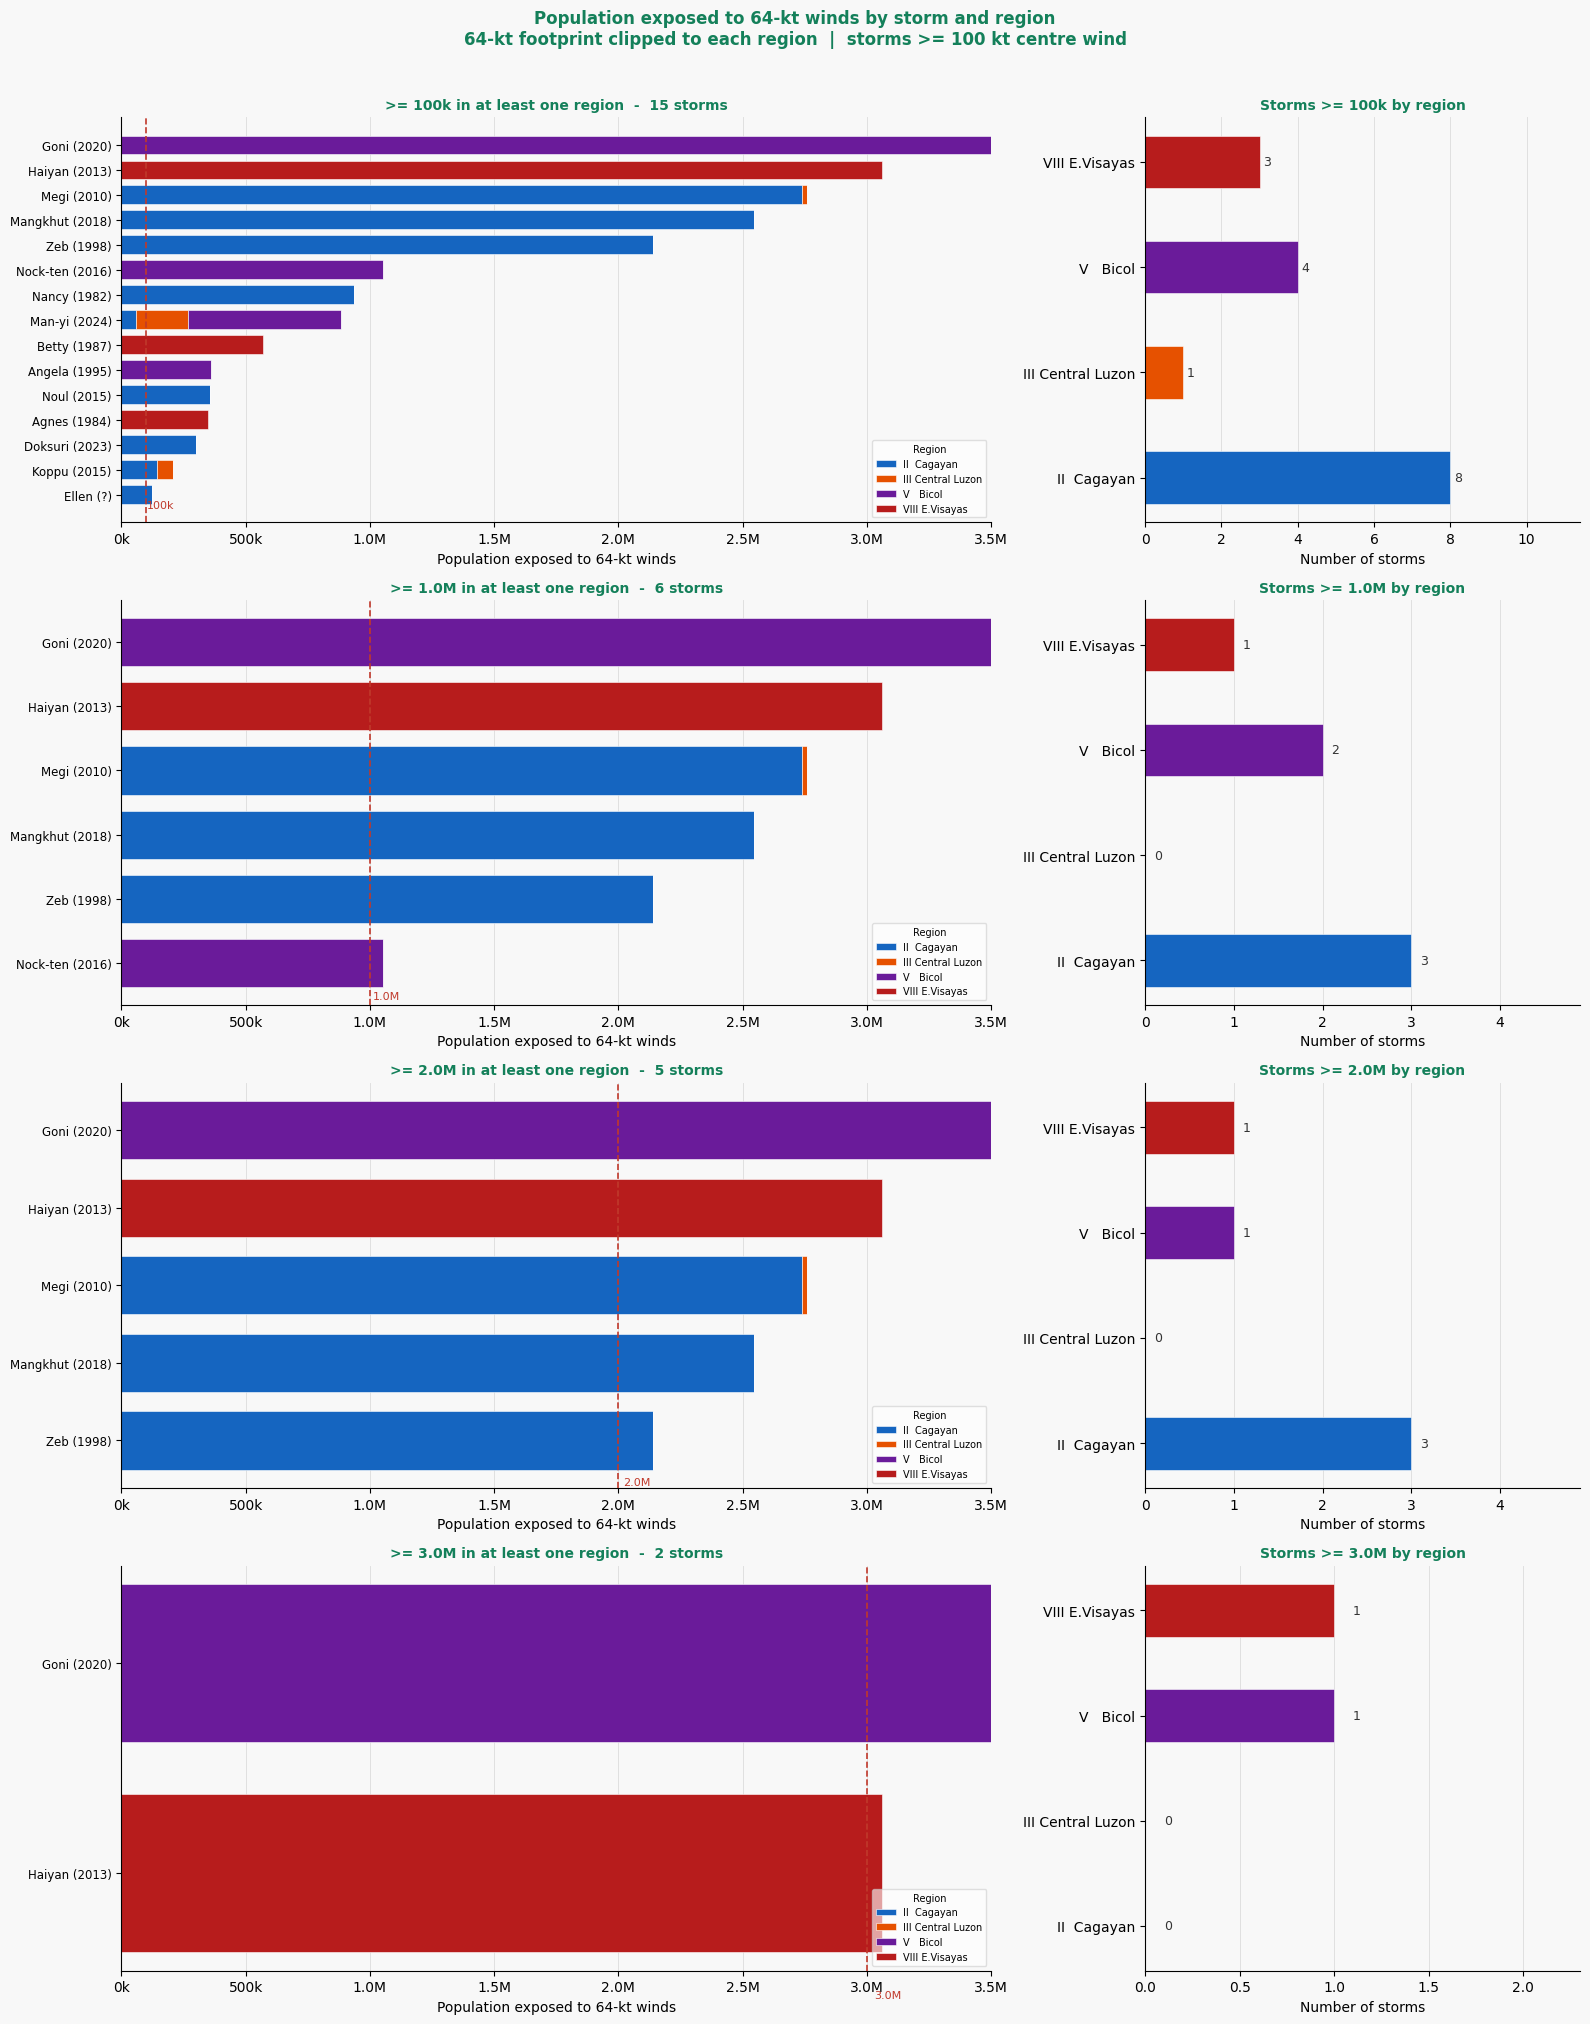

In [32]:
# ── Storms and population by region at each threshold ─────────────────────────
POP_THRESHOLDS = [100_000, 1_000_000, 2_000_000, 3_000_000]

short_names = {
    "Region II (Cagayan Valley)":    "II  Cagayan",
    "Region III (Central Luzon)":    "III Central Luzon",
    "Region V (Bicol Region)":       "V   Bicol",
    "Region VIII (Eastern Visayas)": "VIII E.Visayas",
}
region_cols  = list(short_names.keys())
colors_bar   = ["#1565C0", "#E65100", "#6A1B9A", "#B71C1C"]

region_exposure["label"] = (
    region_exposure["name"] + " (" + region_exposure["year"].fillna("?") + ")"
)

# Wide form: one row per storm, one column per region
reg_wide = region_exposure.pivot_table(
    index=["storm_id", "label"],
    columns="region",
    values="population_exposed",
    aggfunc="sum",
    fill_value=0,
).reset_index()

fig, axes = plt.subplots(
    len(POP_THRESHOLDS), 2,
    figsize=(16, len(POP_THRESHOLDS) * 5),
    gridspec_kw={"width_ratios": [2, 1]},
)
fig.patch.set_facecolor("#f8f8f8")

def _fmt_pop(v):
    return f"{v/1e6:.1f}M" if v >= 1e6 else f"{v/1e3:.0f}k"

for row, thr in enumerate(POP_THRESHOLDS):
    # Storms where at least one region exceeds the threshold
    exceeded_ids = region_exposure.loc[
        region_exposure["population_exposed"] >= thr, "storm_id"
    ].unique()

    sub = (
        reg_wide[reg_wide["storm_id"].isin(exceeded_ids)]
        .set_index("label")[region_cols]
    )
    # Sort by total across all regions
    sub = sub.loc[sub.sum(axis=1).sort_values(ascending=True).index]

    # ── Left: stacked bar chart ───────────────────────────────────────────────
    ax_s = axes[row, 0]
    ax_s.set_facecolor("#f8f8f8")

    lefts = np.zeros(len(sub))
    for col, color in zip(region_cols, colors_bar):
        vals = sub[col].values
        ax_s.barh(range(len(sub)), vals, left=lefts,
                  color=color, edgecolor="white", linewidth=0.4,
                  height=0.75, label=short_names[col])
        lefts += vals

    # Threshold line
    ax_s.axvline(thr, color="#c0392b", linewidth=1.2, linestyle="--", zorder=5)
    ax_s.text(thr * 1.01, -0.6, _fmt_pop(thr),
              color="#c0392b", fontsize=8, va="bottom")

    ax_s.set_yticks(range(len(sub)))
    ax_s.set_yticklabels(sub.index, fontsize=8.5)
    ax_s.xaxis.set_major_formatter(mticker.FuncFormatter(
        lambda x, _: f"{x/1e6:.1f}M" if x >= 1e6 else f"{x/1e3:.0f}k"
    ))
    ax_s.set_xlabel("Population exposed to 64-kt winds", fontsize=10)
    ax_s.set_title(
        f">= {_fmt_pop(thr)} in at least one region  -  {len(sub)} storms",
        fontsize=10, fontweight="bold", color=HEADER_COLOR,
    )
    ax_s.legend(title="Region", fontsize=7, title_fontsize=7,
                loc="lower right", framealpha=0.6)
    ax_s.spines[["top", "right"]].set_visible(False)
    ax_s.xaxis.grid(True, color="#e0e0e0", linewidth=0.7)
    ax_s.set_axisbelow(True)

    # ── Right: count per region ───────────────────────────────────────────────
    ax_r = axes[row, 1]
    ax_r.set_facecolor("#f8f8f8")

    region_counts = (
        region_exposure[region_exposure["population_exposed"] >= thr]
        .groupby("region")["storm_id"].nunique()
        .reindex(region_cols, fill_value=0)
    )
    bars = ax_r.barh(
        [short_names[r] for r in region_cols],
        region_counts.values,
        color=colors_bar, edgecolor="white", linewidth=0.4, height=0.5,
    )
    for bar, val in zip(bars, region_counts.values):
        ax_r.text(bar.get_width() + 0.1, bar.get_y() + bar.get_height() / 2,
                  str(val), va="center", ha="left", fontsize=9, color="#333")

    ax_r.set_xlabel("Number of storms", fontsize=10)
    ax_r.set_title(
        f"Storms >= {_fmt_pop(thr)} by region",
        fontsize=10, fontweight="bold", color=HEADER_COLOR,
    )
    ax_r.set_xlim(0, region_counts.max() * 1.3 + 1)
    ax_r.spines[["top", "right"]].set_visible(False)
    ax_r.xaxis.grid(True, color="#e0e0e0", linewidth=0.7)
    ax_r.set_axisbelow(True)

plt.suptitle(
    f"Population exposed to 64-kt winds by storm and region\n"
    f"64-kt footprint clipped to each region  |  storms >= {KT_THRESHOLD:.0f} kt centre wind",
    fontsize=12, fontweight="bold", color=HEADER_COLOR, y=1.01,
)
plt.tight_layout()
plt.show()

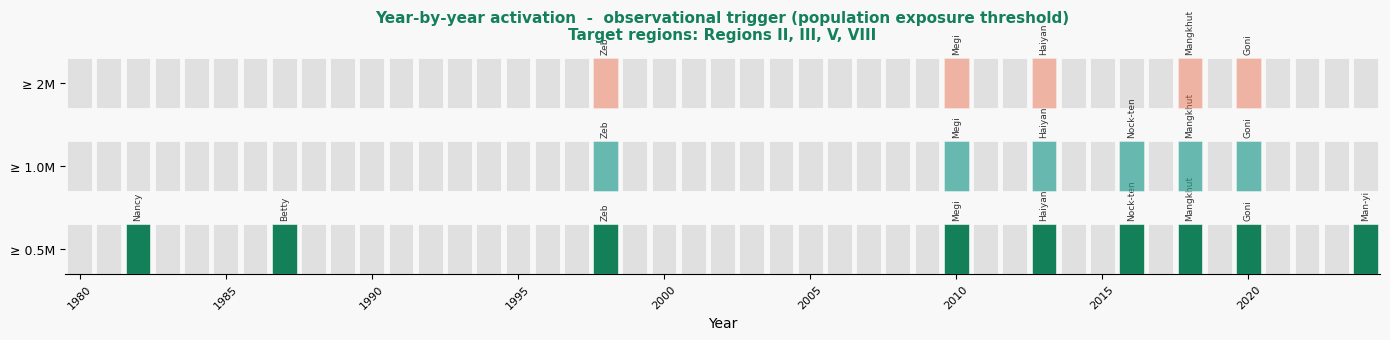

  ≥ 0.5M:  9 seasons  RP ≈ 5.0 yr  [1982, 1987, 1998, 2010, 2013, 2016, 2018, 2020, 2024]
  ≥ 1.0M:  6 seasons  RP ≈ 7.5 yr  [1998, 2010, 2013, 2016, 2018, 2020]
    ≥ 2M:  5 seasons  RP ≈ 9.0 yr  [1998, 2010, 2013, 2018, 2020]


In [29]:
# ── Year-by-year activation timeline ─────────────────────────────────────────
# Using 3 illustrative population thresholds
THRESHOLD_LOW  =   500_000
THRESHOLD_MID  = 1_000_000
THRESHOLD_HIGH = 2_000_000

all_years = list(range(START_YEAR, END_YEAR + 1))

def activated_years(threshold):
    above = exposure_with_year[exposure_with_year["population_exposed"] >= threshold]
    return set(above["year_int"].dropna().astype(int))

act_low  = activated_years(THRESHOLD_LOW)
act_mid  = activated_years(THRESHOLD_MID)
act_high = activated_years(THRESHOLD_HIGH)

fig, ax = plt.subplots(figsize=(14, 3.5))
fig.patch.set_facecolor("#f8f8f8")
ax.set_facecolor("#f8f8f8")

labels = [
    (f"≥ {THRESHOLD_LOW/1e6:.1f}M",  act_low,  "#14805a", 1.0),
    (f"≥ {THRESHOLD_MID/1e6:.1f}M",  act_mid,  "#2a9d8f", 0.7),
    (f"≥ {THRESHOLD_HIGH/1e6:.0f}M", act_high, "#e76f51", 0.5),
]

y_pos = {lbl: i for i, (lbl, _, _, _) in enumerate(labels)}

for lbl, act_set, color, alpha in labels:
    y = y_pos[lbl]
    for yr in all_years:
        if yr in act_set:
            # Find storm names
            names = exposure_with_year[
                (exposure_with_year["year_int"] == yr) &
                (exposure_with_year["population_exposed"] >= {
                    f"≥ {THRESHOLD_LOW/1e6:.1f}M":  THRESHOLD_LOW,
                    f"≥ {THRESHOLD_MID/1e6:.1f}M":  THRESHOLD_MID,
                    f"≥ {THRESHOLD_HIGH/1e6:.0f}M": THRESHOLD_HIGH,
                }[lbl])
            ]["name"].tolist()
            ax.bar(yr, 0.6, bottom=y - 0.3, color=color, alpha=alpha,
                   width=0.85, zorder=3, edgecolor="white", linewidth=0.4)
            ax.text(yr, y + 0.35, ", ".join(names[:2]),
                    ha="center", va="bottom", fontsize=6.5, color="#333",
                    rotation=90)
        else:
            ax.bar(yr, 0.6, bottom=y - 0.3, color="#e0e0e0", width=0.85,
                   zorder=2, edgecolor="white", linewidth=0.4)

ax.set_yticks([y_pos[lbl] for lbl, *_ in labels])
ax.set_yticklabels([lbl for lbl, *_ in labels], fontsize=9)
ax.set_xlim(START_YEAR - 0.5, END_YEAR + 0.5)
ax.set_xlabel("Year", fontsize=10)
ax.set_title(
    "Year-by-year activation  -  observational trigger (population exposure threshold)\n"
    "Target regions: Regions II, III, V, VIII",
    fontsize=11, fontweight="bold", color=HEADER_COLOR,
)
ax.spines[["top", "right", "left"]].set_visible(False)
ax.tick_params(axis="x", labelsize=8, rotation=45)
plt.tight_layout()
plt.show()

for lbl, act_set, _, _ in labels:
    rp = N_YEARS / len(act_set) if act_set else float("inf")
    print(f"{lbl:>8}: {len(act_set):>2} seasons  RP ≈ {rp:.1f} yr  {sorted(act_set)}")

Worst storm: Goni (2020)  -  3,501,347 people  65 munis


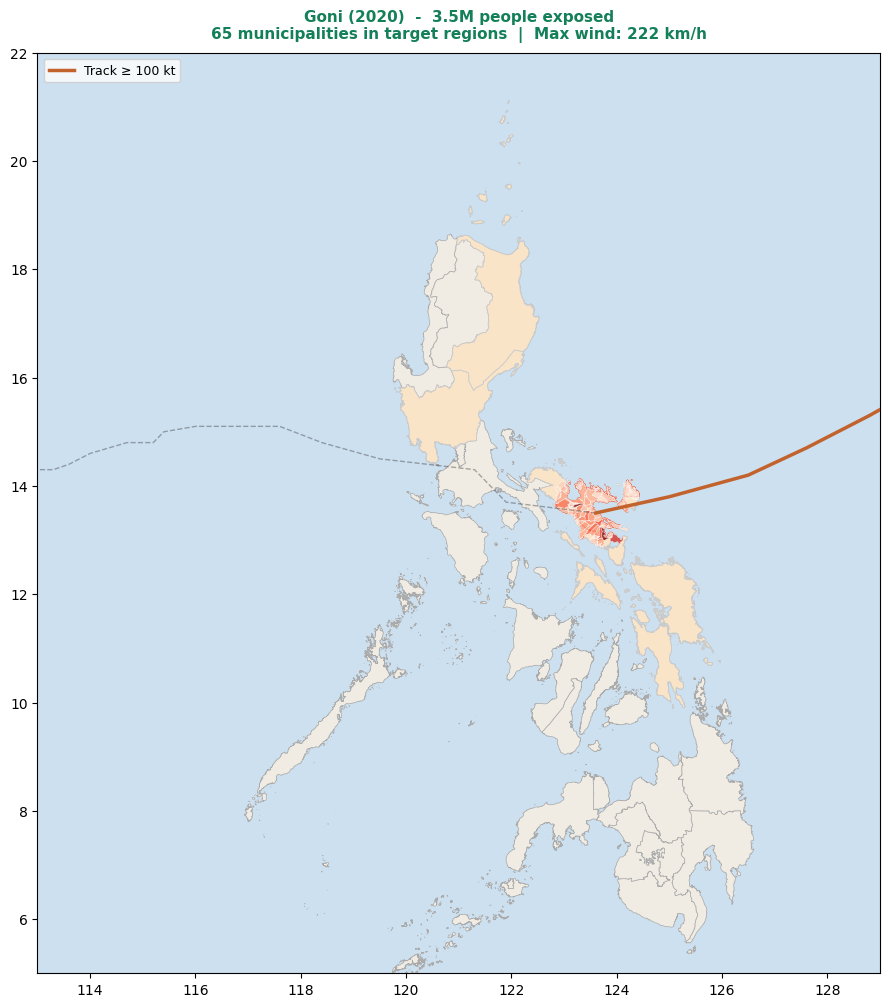

In [30]:
# ── Map: worst-case storm in target regions ───────────────────────────────────
worst_storm = exposure.iloc[0]
worst_id    = worst_storm["storm_id"]
print(f"Worst storm: {worst_storm['name']} ({worst_storm['year']})  -  "
      f"{worst_storm['population_exposed']:,.0f} people  {worst_storm['n_munis']} munis")

worst_track   = tracks_hist[tracks_hist["storm_id"] == worst_id].sort_values("valid_time")
worst_intense = worst_track[worst_track["wind_speed"] >= KT_THRESHOLD]
worst_line    = LineString(list(zip(worst_track.geometry.x, worst_track.geometry.y)))

worst_muni_idx = joined[joined["storm_id"] == worst_id].index.unique()
worst_munis    = admin3_target_pop.loc[worst_muni_idx]
worst_footprint = footprints[footprints["storm_id"] == worst_id].to_crs("EPSG:4326")

fig, ax = plt.subplots(figsize=(9, 11))
ax.set_facecolor("#cde0f0")

# Admin-1 background
phl_admin_1.plot(ax=ax, color="#f0ece3", edgecolor="#aaa", linewidth=0.5, zorder=2)
target_regions_gdf.plot(ax=ax, color="#f9e4c8", edgecolor="#ccc", linewidth=0.6, zorder=3)

# Wind footprint
if not worst_footprint.empty:
    worst_footprint.plot(ax=ax, color="#e76f51", alpha=0.25, zorder=4)
    worst_footprint.boundary.plot(ax=ax, color="#e76f51", linewidth=1.0, zorder=5)

# Exposed municipalities
worst_munis.plot(ax=ax, column="population", cmap="Reds", alpha=0.7,
                 edgecolor="white", linewidth=0.3, zorder=6)

# Track
xs, ys = worst_line.xy
ax.plot(xs, ys, color="#333", linewidth=1.0, alpha=0.4, linestyle="--", zorder=7)
if len(worst_intense) >= 2:
    ax.plot(
        list(worst_intense.geometry.x), list(worst_intense.geometry.y),
        color="#c2622d", linewidth=2.5, zorder=8,
        label=f"Track ≥ {KT_THRESHOLD:.0f} kt",
    )

ax.set_xlim(113, 129); ax.set_ylim(5, 22)
ax.legend(fontsize=9, loc="upper left")
ax.set_title(
    f"{worst_storm['name']} ({worst_storm['year']})  -  "
    f"{worst_storm['population_exposed']/1e6:.1f}M people exposed\n"
    f"{worst_storm['n_munis']} municipalities in target regions  |  "
    f"Max wind: {worst_storm['max_wind_kmh']:.0f} km/h",
    fontsize=11, fontweight="bold", color=HEADER_COLOR, pad=10,
)
plt.tight_layout()
plt.show()

In [31]:
# ── Summary table ─────────────────────────────────────────────────────────────
print("=" * 70)
print("OBSERVATIONAL TRIGGER  -  SUMMARY")
print(f"Record: {START_YEAR}-{END_YEAR} ({N_YEARS} years)")
print(f"Regions: {', '.join(target_regions_gdf['adm1_name'].tolist())}")
print(f"Method: 64-kt wind footprint (mean-filled radii) clipped to target regions")
print(f"Total population in target regions: {total_pop:,.0f}")
print("=" * 70)
print()
print("Return period by population threshold:")
print(
    sweep_df.assign(
        threshold=lambda d: d["threshold"].apply(
            lambda v: f"{v/1e6:.2f}M" if v >= 1e6 else f"{v/1e3:.0f}k"
        )
    ).to_string(index=False)
)
print()
print("Top 15 storms (population exposure in target regions):")
display(
    exposure[["name", "year", "max_wind_kmh", "n_munis", "population_exposed"]]
    .head(15)
    .rename(columns={
        "max_wind_kmh": "max_wind_km/h",
        "n_munis": "municipalities",
        "population_exposed": "population",
    })
    .assign(population=lambda d: d["population"].apply(lambda v: f"{v:,.0f}"))
)

OBSERVATIONAL TRIGGER  -  SUMMARY
Record: 1980-2024 (45 years)
Regions: Region II (Cagayan Valley), Region III (Central Luzon), Region V (Bicol Region), Region VIII (Eastern Visayas)
Method: 64-kt wind footprint (mean-filled radii) clipped to target regions
Total population in target regions: 42,324,903

Return period by population threshold:
threshold  n_seasons  rp_yr  storms
     100k         14    3.2      16
     250k         13    3.5      13
     500k          9    5.0       9
     750k          8    5.6       8
    1.00M          6    7.5       6
    1.50M          5    9.0       5
    2.00M          5    9.0       5
    3.00M          2   22.5       2
    5.00M          0    inf       0

Top 15 storms (population exposure in target regions):


,name,year,max_wind_km/h,municipalities,population
1,Goni,2020,222.2,65,"3,501,347"
2,Haiyan,2013,231.5,87,"3,062,238"
3,Megi,2010,231.5,70,"2,759,613"
4,Mangkhut,2018,203.7,73,"2,547,622"
5,Zeb,1998,203.7,53,"2,140,650"
6,Nock-ten,2016,194.5,35,"1,053,152"
7,Nancy,1982,185.2,26,"936,323"
8,Man-yi,2024,194.5,36,"882,887"
9,Betty,1987,203.7,29,"570,387"
10,Angela,1995,213.0,14,"361,450"
